# Comparing Different Search Strategies: Maze

Notes on breaking ties: 

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



Position(0,0): X
Position(8,1):  


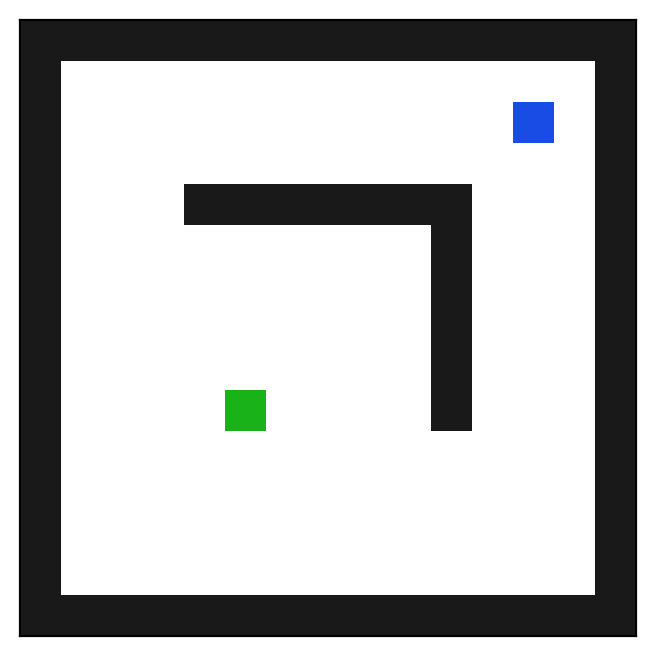

In [1]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [2]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments

### BFS

CPU times: total: 0 ns
Wall time: 1.01 ms


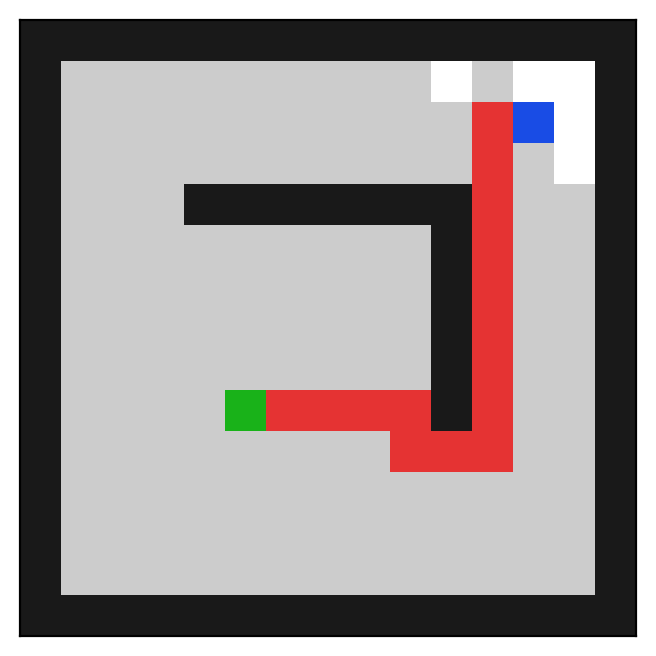

['E',
 'E',
 'E',
 'E',
 'S',
 'E',
 'E',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'N',
 'E']

In [3]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
result['actions']

### DFS 

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

CPU times: total: 0 ns
Wall time: 710 μs


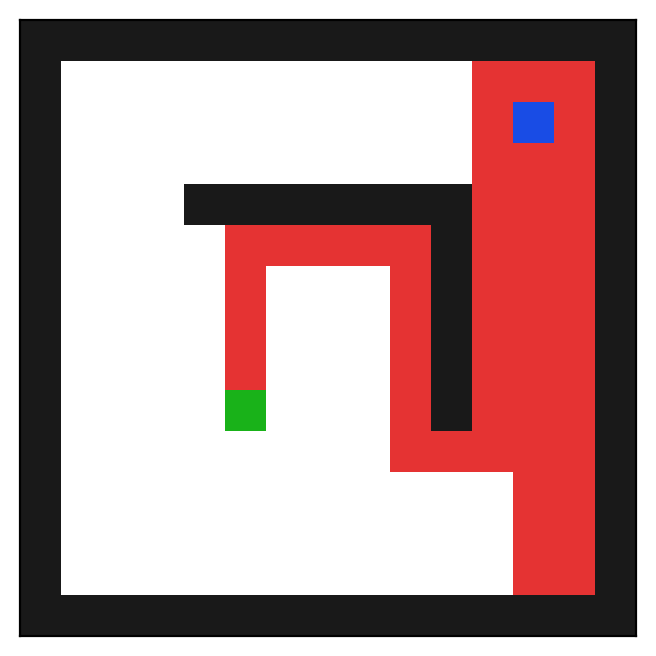

In [4]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough! 
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

CPU times: total: 0 ns
Wall time: 489 μs


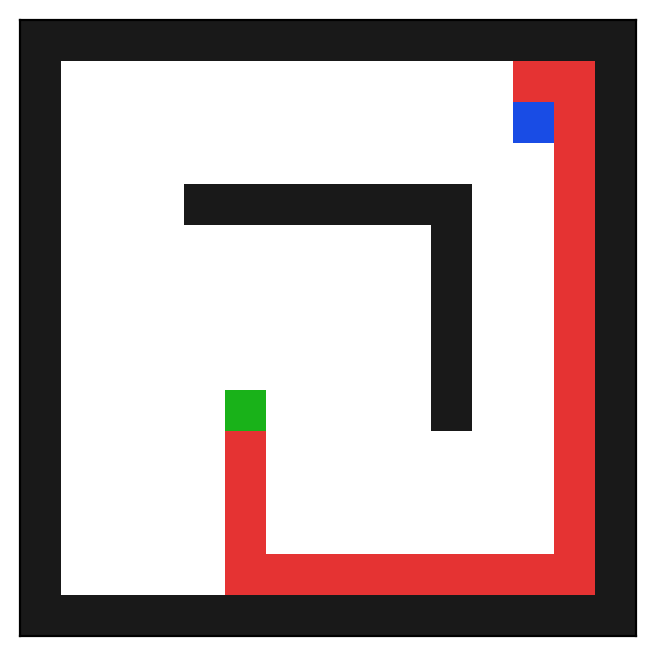

In [ ]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal, 
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

CPU times: total: 15.6 ms
Wall time: 39.1 ms


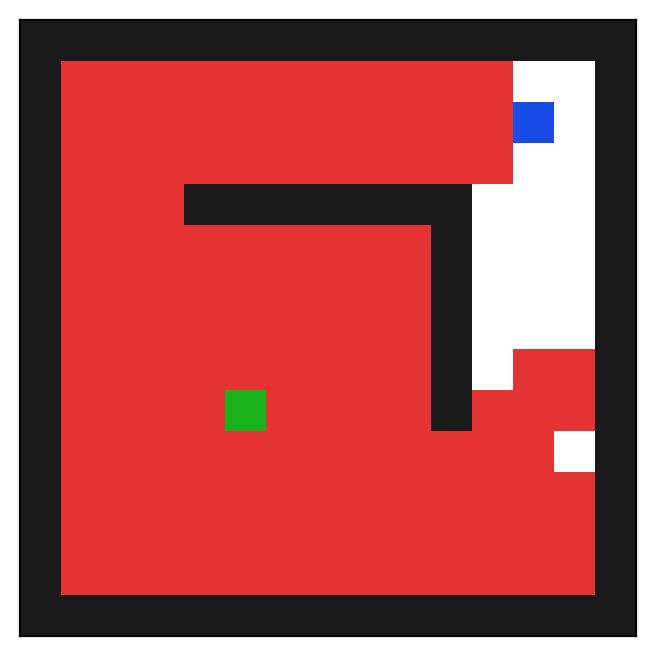

CPU times: total: 0 ns
Wall time: 6.95 ms


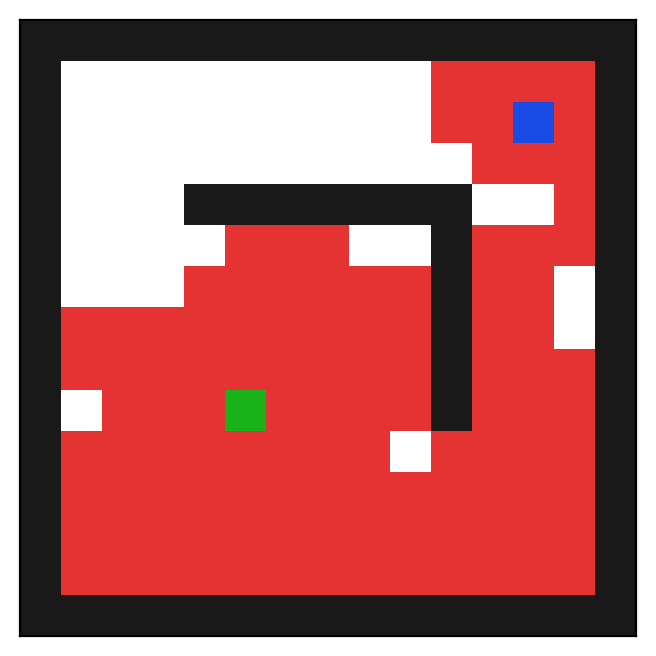

CPU times: total: 0 ns
Wall time: 9.12 ms


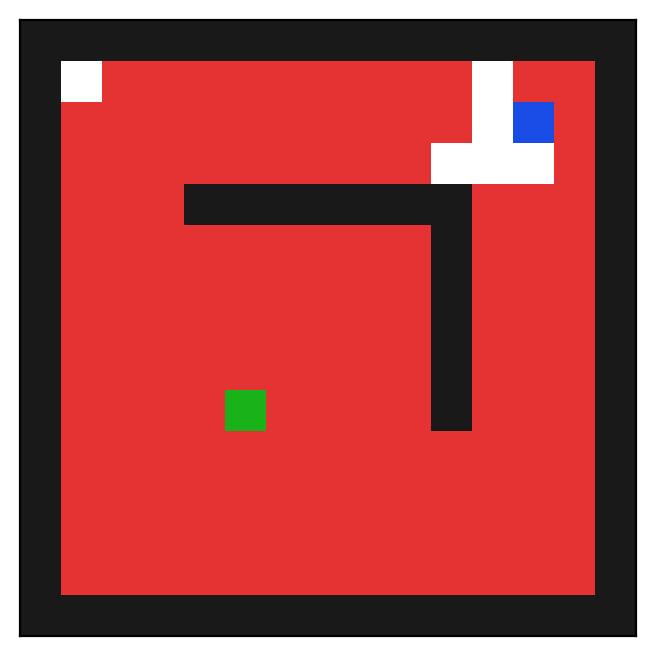

CPU times: total: 0 ns
Wall time: 3.16 ms


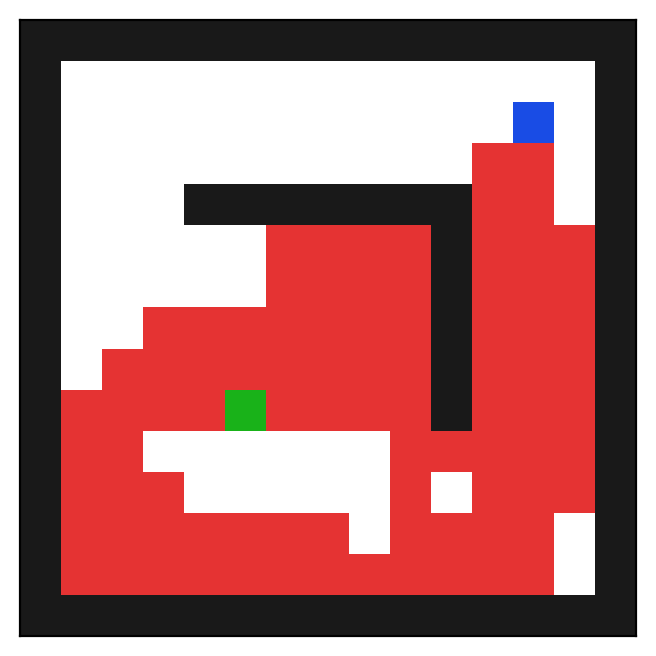

CPU times: total: 15.6 ms
Wall time: 3.84 ms


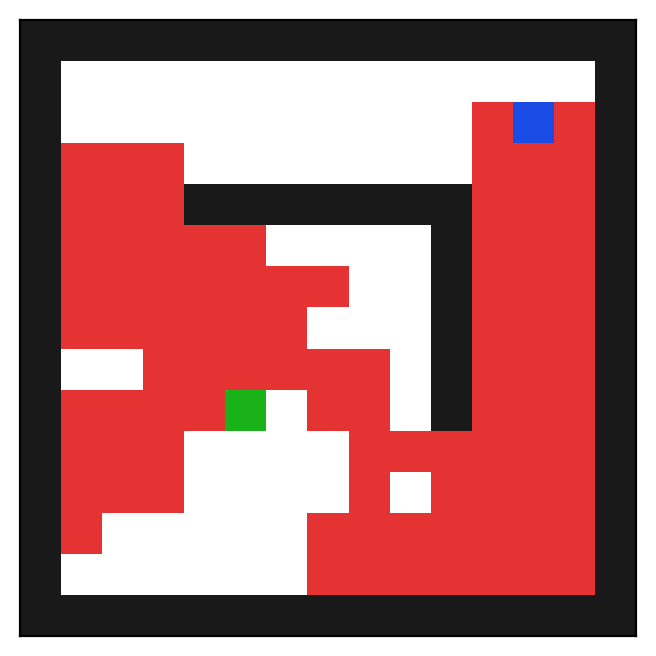

In [5]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 100000, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

CPU times: total: 3.08 s
Wall time: 3.23 s
Solutions have path_lengths of [32, 86, 68, 74, 58, 66, 32, 32, 58, 72, 64, 40, 68, 74, 64, 102, 76, 44, 44, 58, 100, 84, 64, 34, 52, 84, 34, 60, 48, 38, 62, 102, 64, 50, 70, 42, 36, 54, 72, 56, 50, 84, 50, 58, 36, 48, 58, 94, 88, 74, 54, 60, 70, 54, 46, 48, 72, 64, 78, 32, 80, 34, 66, 68, 52, 84, 92, 64, 50, 38, 46, 82, 54, 92, 78, 48, 70, 106, 46]


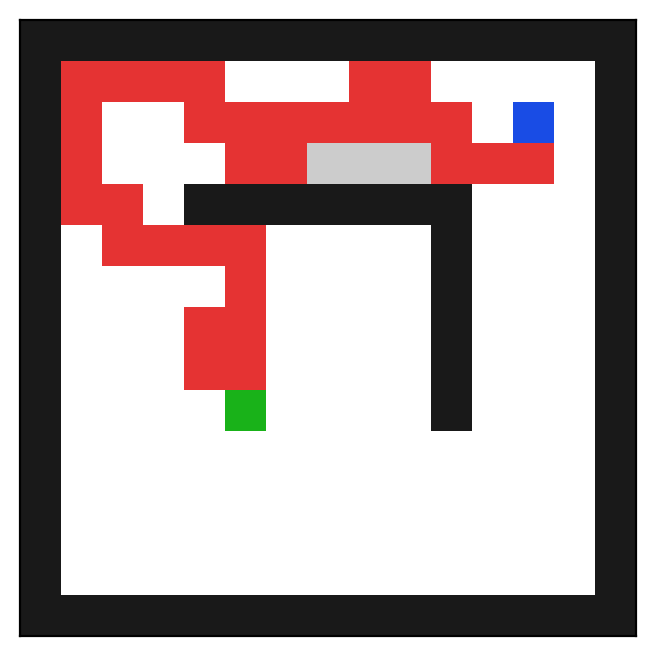

In [7]:
ts.set_order(random = True)

N = 100
%time results = [ ts.DFS(maze, max_tries = 10000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

CPU times: total: 0 ns
Wall time: 1.7 ms
No solution found!


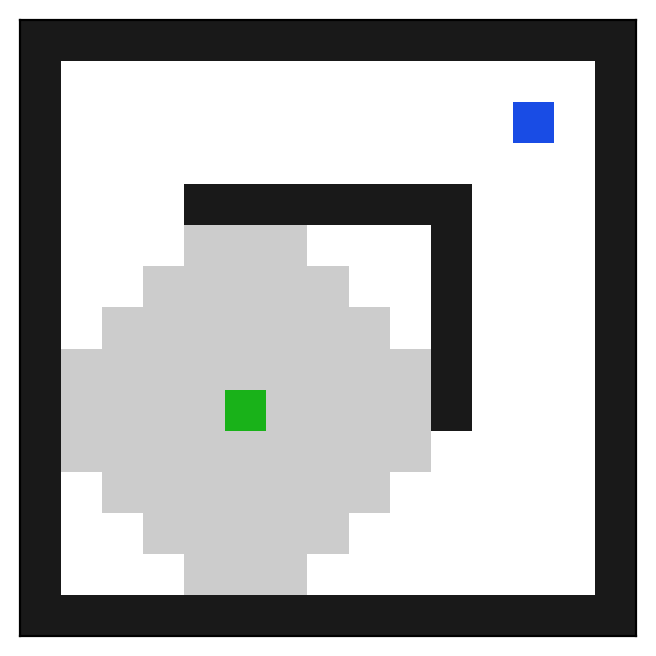

In [8]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

# Bài 4

In [9]:
# ===== Bài 4: khảo sát Depth-Limited DFS =====
import time
import pandas as pd
import matplotlib.pyplot as plt

def load_maze(name):
    """Đọc mê cung từ file <name>_maze.txt (đường dẫn tương đối)."""
    return parse_maze(open(f"{name}_maze.txt").read())

def cost(r):
    return None if r["path"] is None else len(r["path"]) - 1

def summary(runs):
    """Bảng tóm tắt: path cost, nút mở rộng, max depth, max frontier, thời gian."""
    return pd.DataFrame([{"thuật toán": k, "path cost": v["cost"], "nút mở rộng": v["expanded"],
                          "max depth": v["max_depth"], "max frontier": v["max_frontier"],
                          "thời gian (ms)": round(v["time"] * 1000, 2)} for k, v in runs.items()])

mz = load_maze("small")
ts.set_order("NESW")                                  # cố định thứ tự hướng đi để kết quả lặp lại được
ref = ts.best_first_search(mz, strategy="BFS", debug=False, vis=False)
d_opt = ref["cost"]                                   # độ sâu lời giải tối ưu d (BFS tối ưu khi chi phí bước bằng nhau)
print("Độ sâu lời giải tối ưu d (từ BFS) =", d_opt)

rows = []
for L in [5, 10, 20, 30, d_opt - 1, d_opt, d_opt + 10, 2 * d_opt]:
    ts.set_order("NESW")
    r = ts.DFS(mz, limit=L, frontier_option=2, max_tries=100000, vis=False)
    rows.append({"limit": L, "tìm thấy": r["path"] is not None, "path cost": r["cost"],
                 "nút mở rộng": r["expanded"], "max frontier": r["max_frontier"]})
table_dls = pd.DataFrame(rows)
display(table_dls)
found = table_dls[table_dls["tìm thấy"]]
print(f"-> limit < d = {d_opt}: không tìm thấy lời giải. Limit nhỏ nhất tìm thấy trong bảng = {found['limit'].min()} "
      f"(path cost {found.iloc[0]['path cost']}); với limit lớn nhất path cost = {found.iloc[-1]['path cost']}.")

Độ sâu lời giải tối ưu d (từ BFS) = 19


,limit,tìm thấy,path cost,nút mở rộng,max frontier
0,5,False,NaN,19,3
1,10,False,NaN,53,5
2,20,True,19.0,79,5
3,30,True,19.0,103,6
4,18,False,NaN,125,5
5,19,True,19.0,76,5
6,29,True,19.0,101,6
7,38,True,37.0,69,5


-> limit < d = 19: không tìm thấy lời giải. Limit nhỏ nhất tìm thấy trong bảng = 19 (path cost 19.0); với limit lớn nhất path cost = 37.0.


### Nhận xét: Depth-Limited DFS (mê cung `small`, độ sâu tối ưu d = 19)

Kết quả bảng ở trên (thứ tự hướng cố định `NESW`, `frontier_option = 2`):

| limit | 5 | 10 | 18 | 19 | 20 | 29 | 30 | 38 |
|---|---|---|---|---|---|---|---|---|
| tìm thấy | Không | Không | Không | Có | Có | Có | Có | Có |
| path cost | – | – | – | 19 | 19 | 19 | 19 | **37** |
| nút mở rộng | 19 | 53 | 125 | 76 | 79 | 101 | 103 | 69 |

* **Không đầy đủ khi limit quá nhỏ:** với `limit = 5, 10, 18` (đều nhỏ hơn `d = 19`) DLS không tìm thấy lời giải dù lời giải tồn tại (nằm ở độ sâu 19). Limit nhỏ nhất tìm thấy trong bảng là 19 đúng bằng `d`.
* **Không bảo đảm tối ưu khi limit lớn:** với `limit = 38` DLS tìm được đường có path cost **37**, dài hơn tối ưu 18 bước (gần gấp đôi), vì DFS đi theo nhánh nào gặp trước chứ không tìm đường ngắn nhất. Ở các limit 19, 20, 29, 30 kết quả tình cờ bằng 19, đó là do thứ tự hướng `NESW` chứ không phải do DLS bảo đảm tối ưu.
* **Chi phí:** một lần DLS thất bại phải duyệt hết cây tới độ sâu `limit` nên tốn nhiều hơn lần thành công: `limit = 18` (thất bại) mở rộng 125 nút, nhiều hơn `limit = 19` (thành công) chỉ 76 nút.
* → Không biết trước `d` nên không thể chọn limit đúng ngay; đây là lý do cần **IDS** (tự tăng limit).

### IDS

__Notes:__ 

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

CPU times: total: 3.78 s
Wall time: 3.86 s


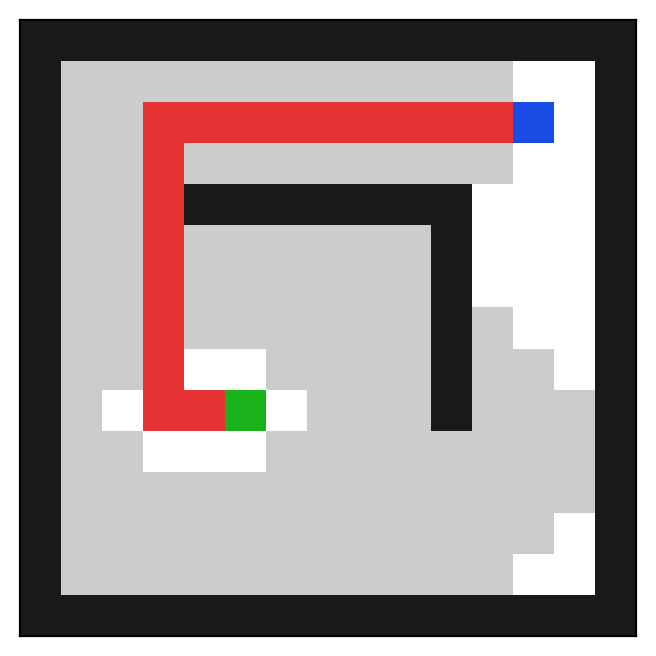

In [10]:
ts.set_order(random = True)

%time result = ts.IDS(maze, frontier_option = 2, max_tries = 100000)
ts.show_path(maze, result)

Giới hạn độ sâu khi tìm thấy lời giải : 19
Số vòng DLS đã chạy                   : 20
Số lần TĂNG giới hạn trước khi thấy   : 19   (limit bắt đầu từ 0)
Path cost IDS = 19   |   path cost BFS = 19
Tổng nút mở rộng IDS = 1052   |   BFS = 93
Max frontier IDS = 5   |   BFS = 9


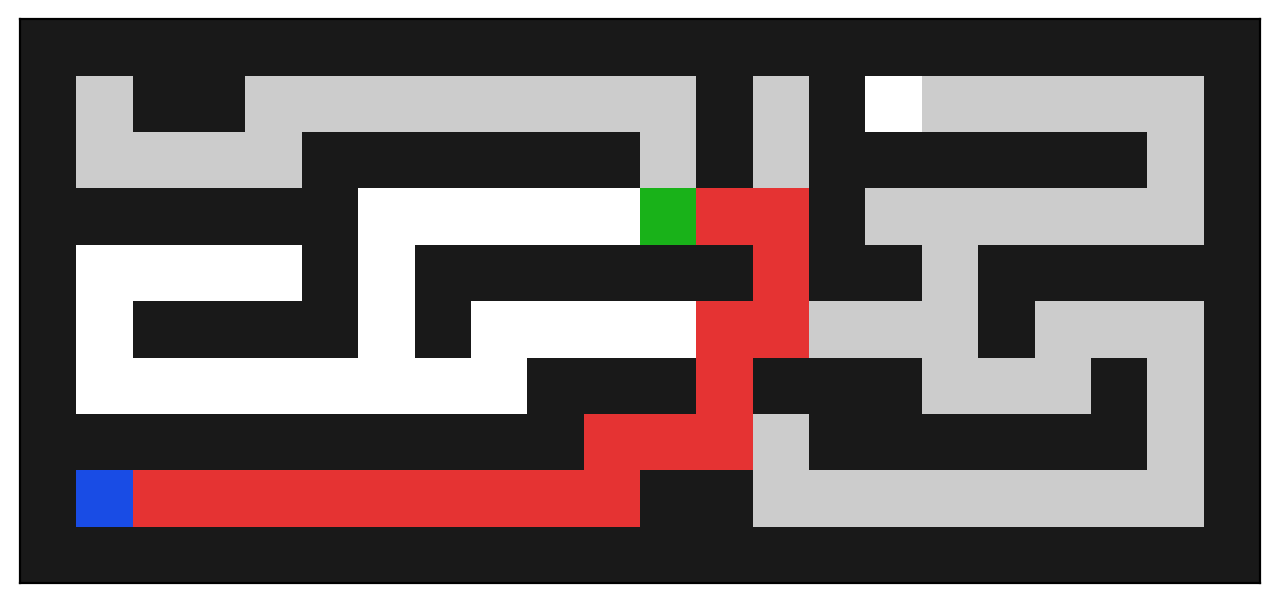

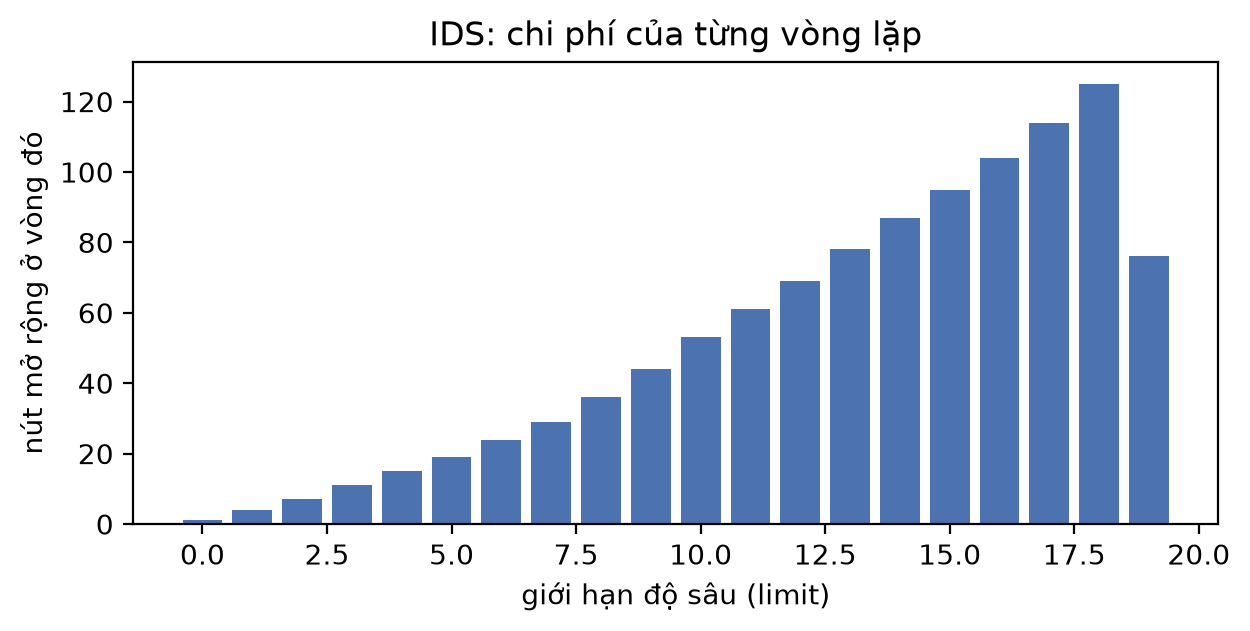

In [11]:
# ===== chạy IDS, ghi lại số lần tăng giới hạn độ sâu =====
ts.set_order("NESW")
ids = ts.IDS(mz, frontier_option=2, max_tries=100000)

print(f"Giới hạn độ sâu khi tìm thấy lời giải : {ids['final_limit']}")
print(f"Số vòng DLS đã chạy                   : {ids['iterations']}")
print(f"Số lần TĂNG giới hạn trước khi thấy   : {ids['final_limit']}   (limit bắt đầu từ 0)")
print(f"Path cost IDS = {ids['cost']}   |   path cost BFS = {d_opt}")
print(f"Tổng nút mở rộng IDS = {ids['expanded']}   |   BFS = {ref['expanded']}")
print(f"Max frontier IDS = {ids['max_frontier']}   |   BFS = {ref['max_frontier']}")
ts.show_path(mz, ids)

lim, cnt = zip(*ids["log"])
plt.figure(figsize=(7, 3)); plt.bar(lim, cnt, color="#4C72B0")
plt.xlabel("giới hạn độ sâu (limit)"); plt.ylabel("nút mở rộng ở vòng đó"); plt.title("IDS: chi phí của từng vòng lặp")
plt.savefig("hinh_bai4_ids_theo_limit.png", dpi=150, bbox_inches="tight"); plt.show()

### Nhận xét: IDS và vì sao IDS kết hợp DFS với BFS

**Kết quả đo được trên `small`:** IDS phải **tăng giới hạn 19 lần** (limit từ 0 lên 19, tổng cộng 20 vòng DLS) mới tìm thấy lời giải ở `limit = 19`. Path cost = 19, bằng đúng BFS nên IDS tối ưu. Tổng nút mở rộng của IDS là **1 052**, so với **93** của BFS (≈ 11,3 lần); `max frontier` của IDS là 5, của BFS là 9.

**Vì sao IDS kết hợp ưu điểm của DFS và BFS:**
1. *Bộ nhớ của DFS:* mỗi vòng chỉ là một DLS, không có bảng `reached`, frontier chỉ giữ đường đi hiện tại cùng các nút anh em chưa thăm → bộ nhớ khoảng `O(b·d)`, trong khi BFS phải lưu `O(bᵈ)` nút.
2. *Tìm theo độ sâu tăng dần như BFS:* IDS thử `limit = 0, 1, 2, …` nên lần đầu có lời giải chính là ở độ sâu nông nhất → đầy đủ và tối ưu khi chi phí bước bằng nhau (cost 19 = cost của BFS).
3. *Cái giá phải trả là thời gian:* các tầng nông bị mở rộng lặp lại ở mọi vòng và IDS không nhớ ô đã thăm nên mở rộng cùng một ô nhiều lần. Theo bảng kết quả cuối notebook: `small` IDS 6,84 ms so với BFS 0,43 ms (≈ 16 lần); `medium` IDS mở rộng 13 103 nút so với 270 của BFS (≈ 48,5 lần), mất 94,02 ms so với 1,14 ms (≈ 82 lần); ở cell *Compare Timing* trên `large` IDS mất 725 470 µs so với 3 791 µs của BFS (≈ 191 lần).
4. *Lưu ý trung thực về bộ nhớ:* ở các mê cung này `max frontier` của BFS vốn đã nhỏ (9 ở `small` và `medium`), nên lợi thế bộ nhớ của IDS chỉ thấy rõ ở `small` (5 so với 9) và hòa ở `medium` (9 so với 9). Lợi thế `O(b·d)` so với `O(bᵈ)` chỉ thật sự lớn khi hệ số phân nhánh lớn.

In [ ]:
# ===== ảnh hưởng của cycle checking lên IDS =====
cfgs = {"(a) kiểm tra đường đi hiện tại (frontier_option=1)": dict(frontier_option=1, max_tries=100000),
        "(b) đường đi + frontier (frontier_option=2)":          dict(frontier_option=2, max_tries=100000),
        "(c) KHÔNG cycle checking (check_cycle=False)":         dict(frontier_option=1, check_cycle=False, max_tries=20000)}
rows = []
for name, kw in cfgs.items():
    ts.set_order("NESW")
    r = ts.IDS(mz, **kw)
    rows.append({"cấu hình": name, "tìm thấy": r["path"] is not None, "path cost": r["cost"],
                 "tổng nút mở rộng": r["expanded"], "max frontier": r["max_frontier"],
                 "thời gian (ms)": round(r["time"] * 1000, 1)})
table_cyc = pd.DataFrame(rows)
display(table_cyc)
print("-> IDS phụ thuộc cơ chế cycle checking của DFS: so sánh cột 'tổng nút mở rộng' và 'thời gian' giữa (a), (b), (c).")

,cấu hình,tìm thấy,path cost,tổng nút mở rộng,max frontier,thời gian (ms)
0,(a) kiểm tra đường đi hiện tại (frontier_optio...,True,19.0,1052,5,5.9
1,(b) đường đi + frontier (frontier_option=2),True,19.0,1052,5,6.9
2,(c) KHÔNG cycle checking (check_cycle=False),False,NaN,1693313,96,3962.0


-> IDS phụ thuộc cơ chế cycle checking của DFS: so sánh cột 'tổng nút mở rộng' và 'thời gian' giữa (a), (b), (c).


### Nhận xét: Ảnh hưởng của cycle checking lên IDS (`small`)

| Cấu hình | Tìm thấy | Path cost | Tổng nút mở rộng | Max frontier | Thời gian |
|---|---|---|---|---|---|
| (a) kiểm tra đường đi hiện tại | Có | 19 | 1 052 | 5 | 5,9 ms |
| (b) đường đi + frontier (`frontier_option = 2`) | Có | 19 | 1 052 | 5 | 6,9 ms |
| (c) không cycle checking | **Không** (hết ngân sách `max_tries`) | – | **1 693 313** | 96 | 3 962 ms |

* **Cycle checking quyết định hiệu năng của IDS:** khi bỏ hoàn toàn (c), DLS vẫn dừng nhờ giới hạn độ sâu nhưng cứ đi tới rồi lui lại giữa hai ô nên sinh ra rất nhiều nút trùng: số nút mở rộng gấp khoảng **1 600 lần** (a) và thời gian gấp khoảng **670 lần**, mà vẫn không tìm ra lời giải trong ngân sách. Như vậy cycle checking không phù hợp (hoặc thiếu) làm sai lệch/làm hỏng kết quả IDS, đúng như ghi chú của notebook.
* **(a) và (b) cho cùng kết quả trên mê cung này** (cùng 1 052 nút). Kiểm tra thêm frontier không giảm được số nút ở đây; thời gian của (b) cao hơn khoảng 1 ms, chủ yếu do chi phí quản lý cấu trúc phụ (một lần đo, chênh lệch nhỏ nên chỉ nên xem là xấp xỉ). Kiểm tra frontier chỉ có lợi khi mê cung có nhiều đường cùng dẫn tới một ô.

### Greedy Best-First Search (GBFS)

In [13]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

CPU times: total: 0 ns
Wall time: 1.91 ms


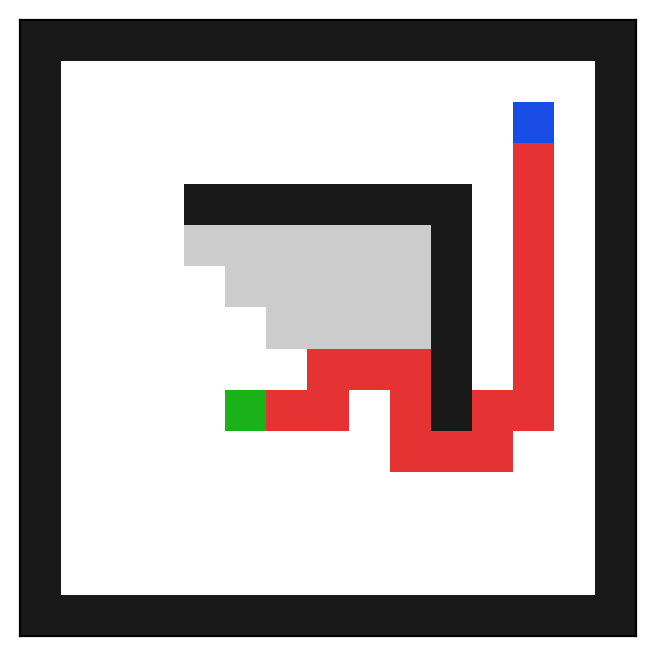

In [14]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

### A* Search

CPU times: total: 0 ns
Wall time: 533 μs


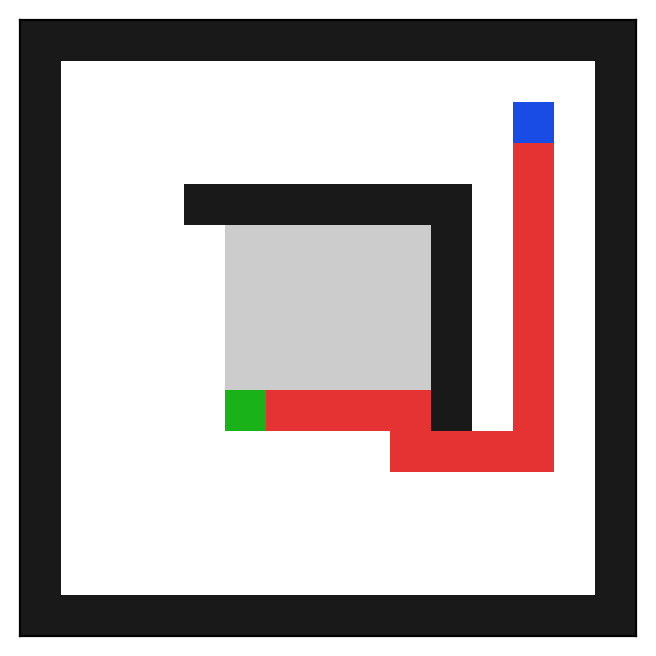

In [15]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

CPU times: total: 0 ns
Wall time: 561 μs


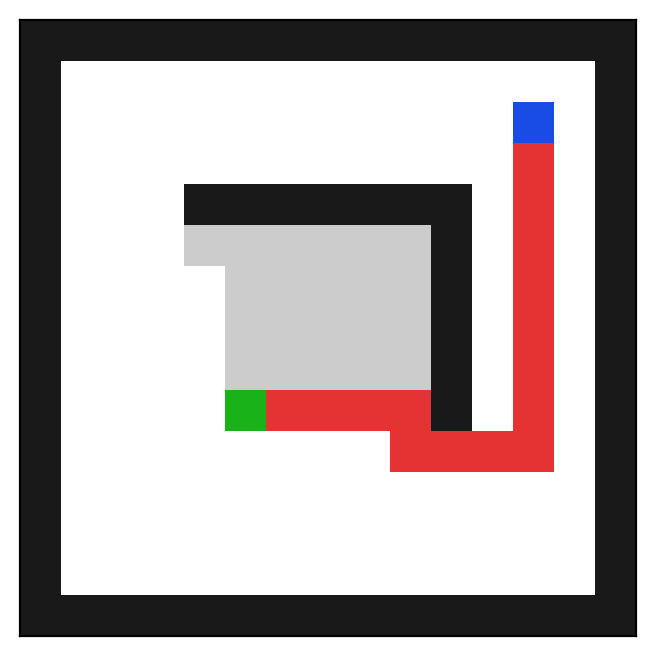

In [16]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 453 μs


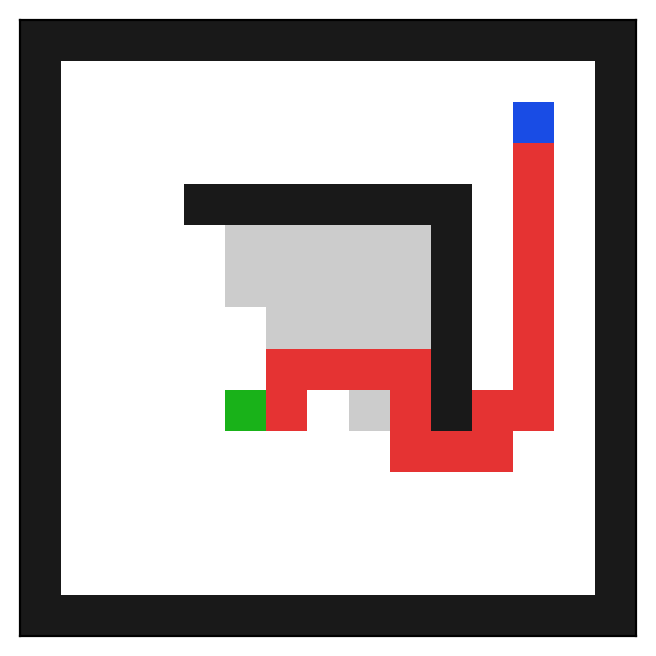

In [17]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 549 μs


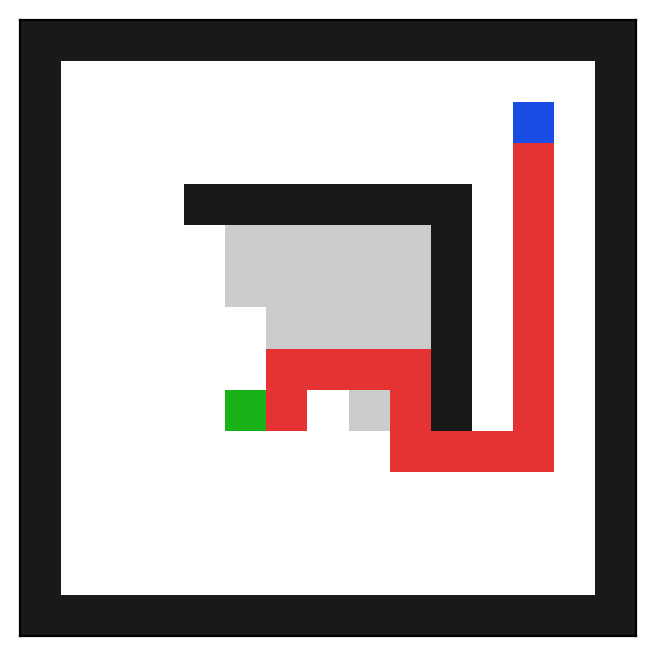

In [18]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)

$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

CPU times: total: 0 ns
Wall time: 856 μs


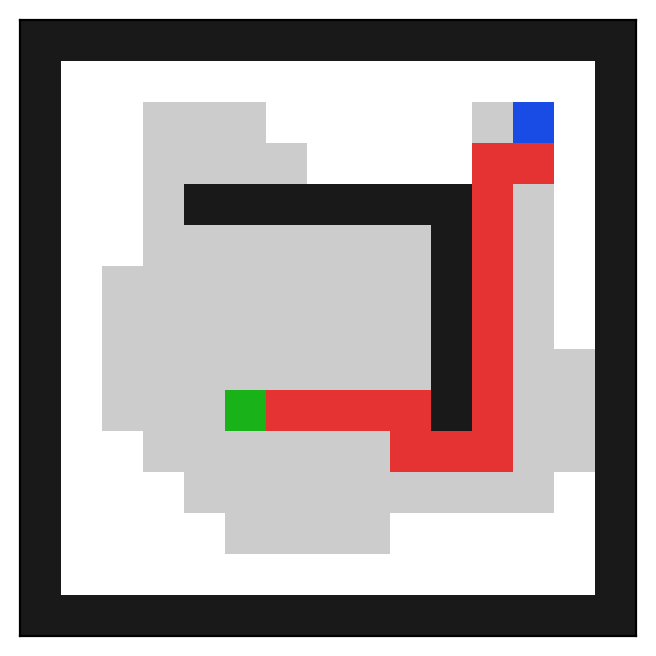

In [19]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 1.24 ms


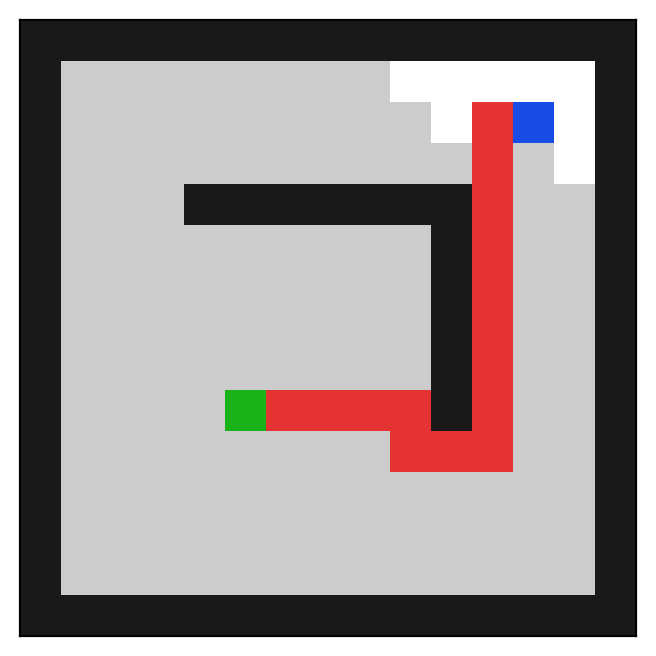

In [20]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

# Bài 5

,thuật toán,path cost,nút mở rộng,max depth,max frontier,thời gian (ms)
0,BFS,68,270,68,9,1.22
1,GBFS,152,156,152,8,0.82
2,A* (w=1),68,218,68,8,1.08
3,Weighted A* (w=5),102,227,102,10,1.17


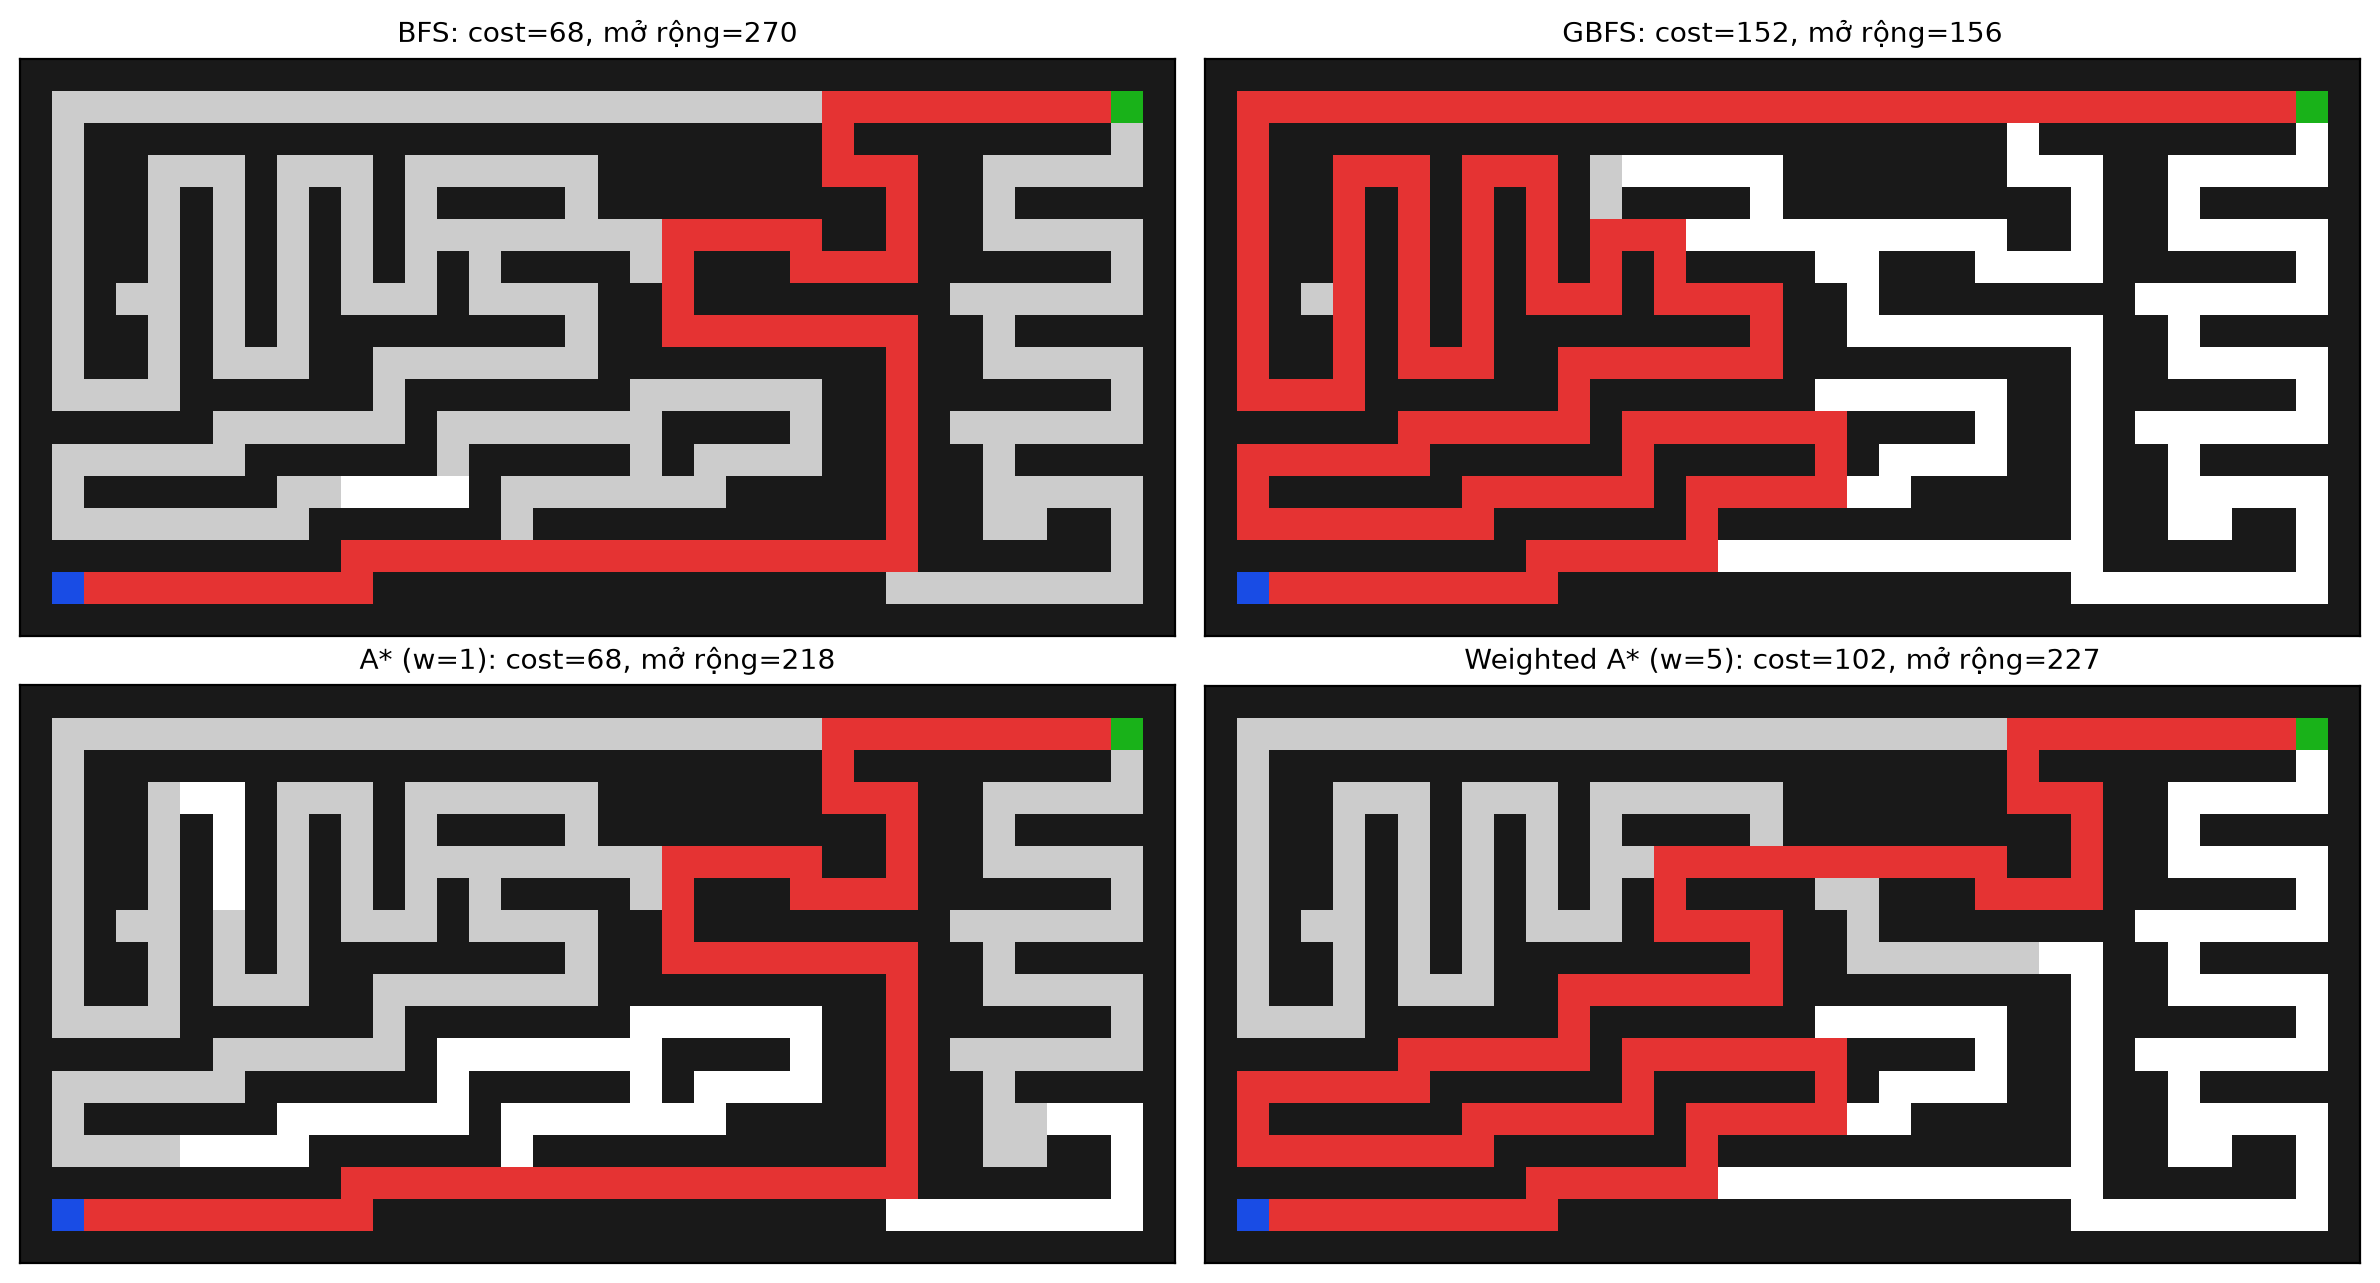

-> BFS cost = 68, A* cost = 68 (A* tối ưu như BFS); GBFS cost = 152; Weighted A* (w=5) cost = 102.
-> Số nút mở rộng: BFS 270, A* 218, GBFS 156, Weighted A* 227.


In [21]:
# ===== Bài 5: GBFS, A*, Weighted A* so với BFS (mê cung medium) =====
mz = load_maze("medium")
ts.heuristic = ts.manhattan
runs = {}
for name, kw in [("BFS", dict(strategy="BFS")), ("GBFS", dict(strategy="GBFS")),
                 ("A* (w=1)", dict(strategy="A*")), ("Weighted A* (w=5)", dict(strategy="A*", W=5))]:
    ts.set_order("NESW")
    runs[name] = ts.best_first_search(mz, debug=False, vis=False, **kw)
display(summary(runs))

fig, axs = plt.subplots(2, 2, figsize=(12, 6.5))
for ax, (name, r) in zip(axs.ravel(), runs.items()):
    ts.show_path(mz, r, ax=ax, title=f"{name}: cost={r['cost']}, mở rộng={r['expanded']}")
plt.tight_layout(); plt.savefig("hinh_bai5_medium_bfs_gbfs_astar.png", dpi=150); plt.show()

print(f"-> BFS cost = {runs['BFS']['cost']}, A* cost = {runs['A* (w=1)']['cost']} (A* tối ưu như BFS); "
      f"GBFS cost = {runs['GBFS']['cost']}; Weighted A* (w=5) cost = {runs['Weighted A* (w=5)']['cost']}.")
print(f"-> Số nút mở rộng: BFS {runs['BFS']['expanded']}, A* {runs['A* (w=1)']['expanded']}, "
      f"GBFS {runs['GBFS']['expanded']}, Weighted A* {runs['Weighted A* (w=5)']['expanded']}.")

# nhận xét GBFS, A\*, Weighted A\*

| Thuật toán | Path cost | Nút mở rộng | Max frontier | Thời gian |
|---|---|---|---|---|
| BFS | 68 | 270 | 9 | 1,22 ms |
| GBFS (Manhattan) | **152** | 156 | 8 | 0,82 ms |
| A\* (w = 1) | 68 | 218 | 8 | 1,08 ms |
| Weighted A\* (w = 5) | **102** | 227 | 10 | 1,17 ms |

* **A\* tối ưu như BFS** (cùng cost 68) nhưng mở rộng ít hơn 52 nút (218 so với 270, giảm ≈ 19 %), vì heuristic Manhattan (admissible) kéo tìm kiếm về phía đích.
* **GBFS chỉ dùng `h(n)`** nên ít nút nhất (156, giảm ≈ 42 % so với BFS) và nhanh nhất, nhưng path cost là **152, gấp ≈ 2,2 lần tối ưu** → không tối ưu vì bỏ qua chi phí đã đi `g(n)`.
* **Weighted A\* (w = 5)** nằm giữa về chất lượng (cost 102, gấp 1,5 lần tối ưu) nhưng trên mê cung này mở rộng **227 nút, không ít hơn A\* (218)** → chỉ mất tối ưu mà không được lợi tốc độ. Xem thêm Task 5.3.
* Trên `L_maze` (cell BFS ở đầu notebook) BFS cho đường 16 bước; trong notebook `04_Maze_BFS_vs_A_Star.ipynb` A\* cũng cho 16 bước.

--- mê cung medium ---


,thuật toán,path cost,nút mở rộng,max depth,max frontier,thời gian (ms)
0,BFS,68,270,68,9,1.26
1,A* Euclidean,68,225,68,8,1.24
2,GBFS Euclidean,152,160,152,8,1.08
3,A* Manhattan,68,218,68,8,1.16
4,GBFS Manhattan,152,156,152,8,0.80


--- mê cung open ---


,thuật toán,path cost,nút mở rộng,max depth,max frontier,thời gian (ms)
0,BFS,54,683,54,25,3.39
1,A* Euclidean,54,517,54,51,3.57
2,GBFS Euclidean,54,55,54,63,0.50
3,A* Manhattan,54,212,54,185,1.63
4,GBFS Manhattan,54,773,57,64,6.02


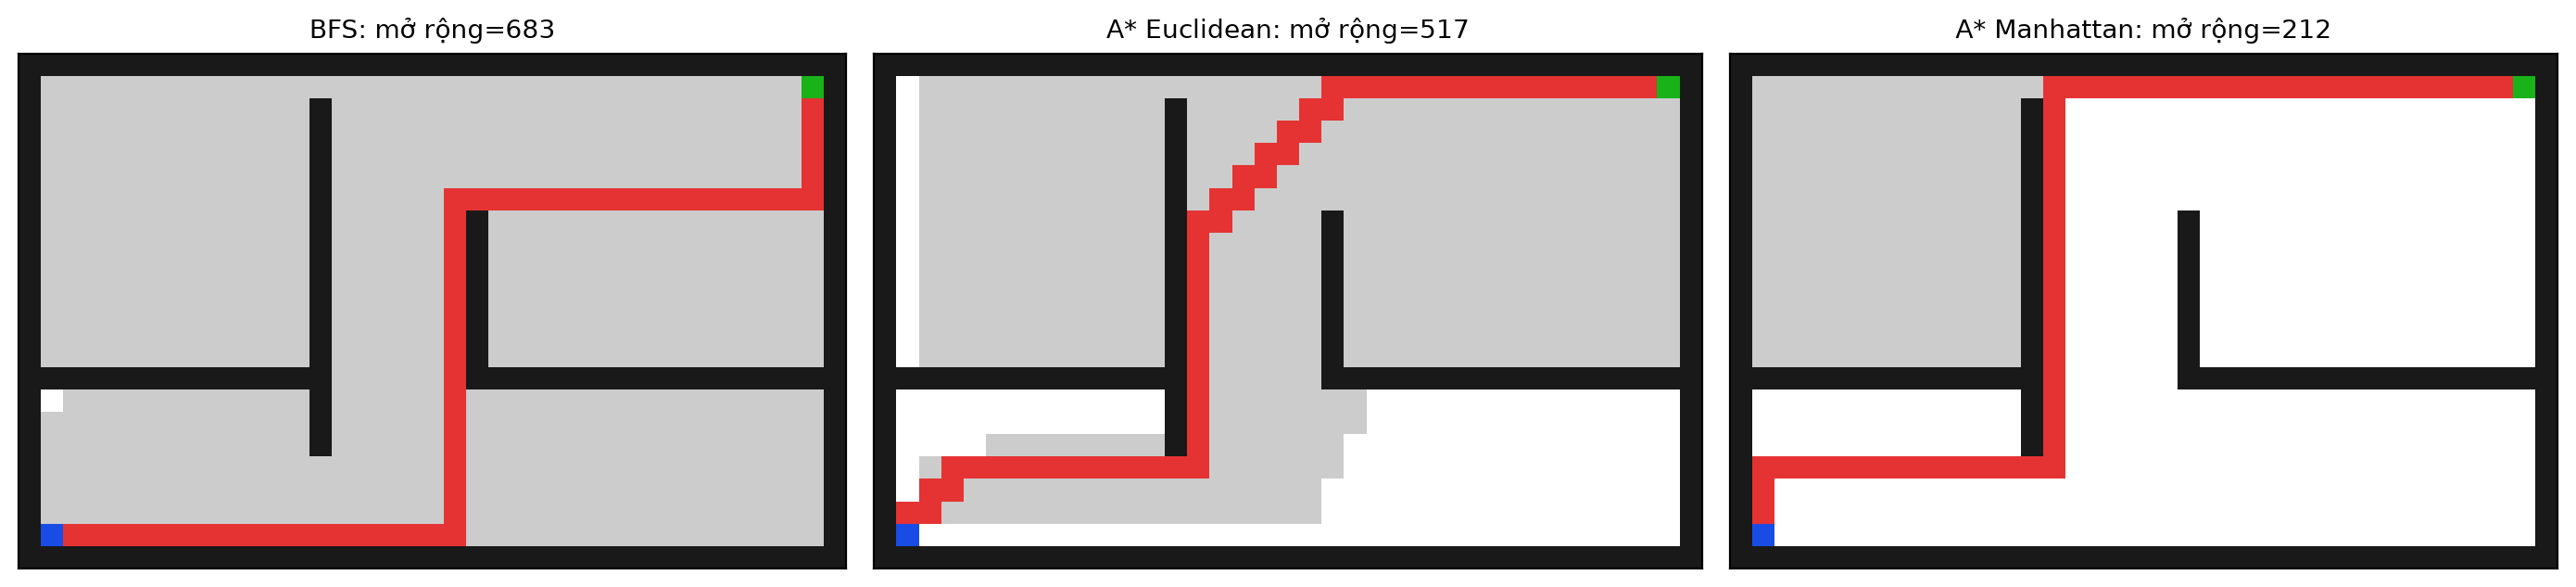

-> open_maze: A* Euclidean mở rộng 517 nút, A* Manhattan 212 nút, BFS 683 nút; cả ba cùng path cost 54.


In [22]:
# ===== A* với heuristic Euclidean và Manhattan (và so với BFS) =====
tables = {}
for mname in ["medium", "open"]:
    mz2 = load_maze(mname)
    rr = {}
    ts.set_order("NESW"); rr["BFS"] = ts.best_first_search(mz2, strategy="BFS", debug=False, vis=False)
    for hname, h in [("Euclidean", ts.euclidean), ("Manhattan", ts.manhattan)]:
        ts.heuristic = h
        ts.set_order("NESW"); rr[f"A* {hname}"] = ts.best_first_search(mz2, strategy="A*", debug=False, vis=False)
        ts.set_order("NESW"); rr[f"GBFS {hname}"] = ts.best_first_search(mz2, strategy="GBFS", debug=False, vis=False)
    ts.heuristic = ts.manhattan
    tables[mname] = rr
    print(f"--- mê cung {mname} ---"); display(summary(rr))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, k in zip(axs, ["BFS", "A* Euclidean", "A* Manhattan"]):
    r = tables["open"][k]
    ts.show_path(load_maze("open"), r, ax=ax, title=f"{k}: mở rộng={r['expanded']}")
plt.tight_layout(); plt.savefig("hinh_bai5_open_bfs_euclid_manhattan.png", dpi=150); plt.show()
o = tables["open"]
print(f"-> open_maze: A* Euclidean mở rộng {o['A* Euclidean']['expanded']} nút, A* Manhattan {o['A* Manhattan']['expanded']} nút, BFS {o['BFS']['expanded']} nút; "
      f"cả ba cùng path cost {o['BFS']['cost']}.")

# Manhattan so với Euclidean

| Mê cung | BFS | A\* Euclidean | A\* Manhattan | GBFS Euclidean | GBFS Manhattan |
|---|---|---|---|---|---|
| `medium` – nút mở rộng | 270 | 225 | **218** | 160 | 156 |
| `open` – nút mở rộng | 683 | 517 | **212** | **55** | 773 |
| `open` – max frontier | 25 | 51 | 185 | 63 | 64 |

* **Cả hai heuristic đều admissible** trên lưới 4 hướng nên A\* đều tối ưu: cost bằng BFS (68 ở `medium`, 54 ở `open`).
* **Với A\*, Manhattan tốt hơn Euclidean.** Trên lưới chỉ đi lên/xuống/trái/phải, chi phí thật tối thiểu (không tính tường) đúng bằng khoảng cách Manhattan, còn Euclidean luôn nhỏ hơn hoặc bằng (đường chéo không tồn tại) nên đánh giá thấp chi phí, `f` kém phân biệt các nút. Hệ quả: ở `open` A\* Euclidean mở rộng 517 nút còn Manhattan chỉ 212 (ít hơn ≈ 59 %); ở `medium` chênh lệch nhỏ (225 so với 218) có thể do mê cung này có ít chỗ trống để heuristic cắt bớt nút (cần xem hình để xác nhận).
* **Với GBFS trên `open` thì ngược lại:** Euclidean chỉ mở rộng 55 nút, trong khi Manhattan mở rộng tới **773 nút, nhiều hơn cả BFS (683)**. Nhiều khả năng do Manhattan cho rất nhiều ô cùng giá trị `h` trên lưới trống, nên khi chỉ dùng `h` (và hòa điểm bằng "nút thêm sau cùng") GBFS bị lan ra nhiều ô; Euclidean cho giá trị khác nhau hơn nên đi thẳng hơn. Vì vậy không thể nói Manhattan luôn tốt hơn: kết luận trên chỉ chắc chắn cho A\*.
* **Đánh đổi bộ nhớ:** ở `open`, A\* Manhattan mở rộng ít nút nhất nhưng `max frontier` lớn nhất (185, so với 25 của BFS và 51 của A\* Euclidean); nhiều nút có cùng `f = g + h` cùng nằm trong frontier.

,maze,w,path cost,nút mở rộng,tối ưu?
0,medium,0.0001,68,269,True
1,medium,0.5000,68,242,True
2,medium,1.0000,68,218,True
3,medium,1.5000,68,230,True
4,medium,2.0000,68,228,True
5,medium,3.0000,68,216,True
6,medium,5.0000,102,227,False
7,medium,10.0000,152,162,False
8,medium,1000.0000,152,158,False
9,open,0.0001,54,683,True


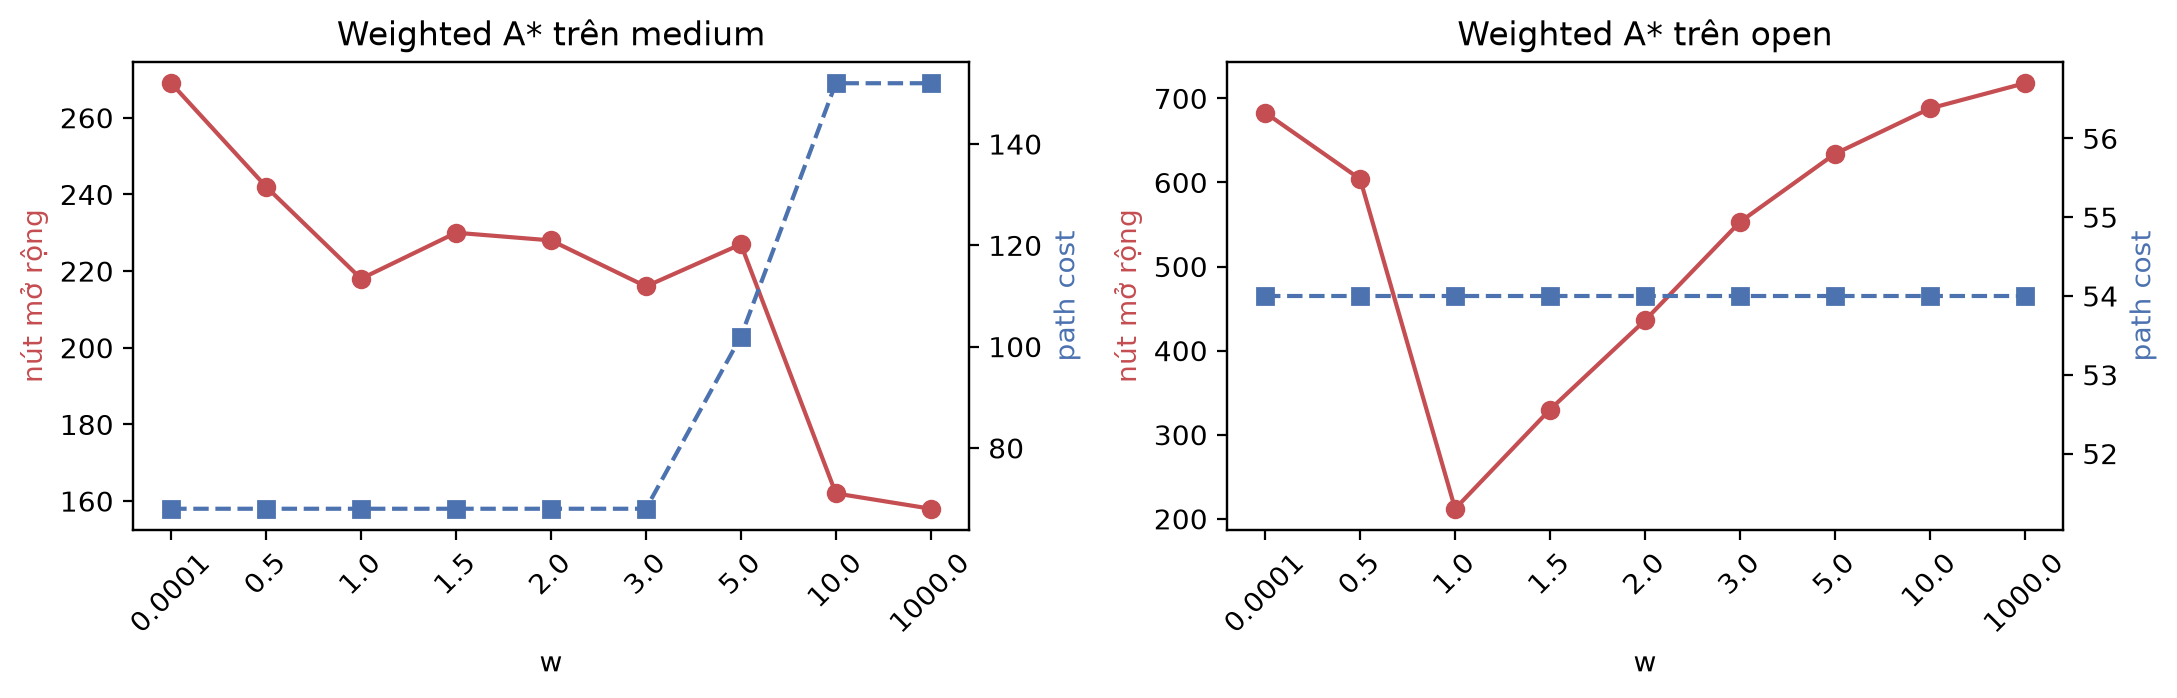

In [23]:
# ===== Thay đổi trọng số w của Weighted A* =====
ws = [0.0001, 0.5, 1, 1.5, 2, 3, 5, 10, 1000]
rows = []
for mname in ["medium", "open"]:
    mz3 = load_maze(mname)
    ts.set_order("NESW"); opt = ts.best_first_search(mz3, strategy="BFS", debug=False, vis=False)["cost"]
    for w in ws:
        ts.heuristic = ts.manhattan
        ts.set_order("NESW")
        r = ts.best_first_search(mz3, strategy="A*", W=w, debug=False, vis=False)
        rows.append({"maze": mname, "w": w, "path cost": r["cost"], "nút mở rộng": r["expanded"],
                     "tối ưu?": r["cost"] == opt})
sweep = pd.DataFrame(rows)
display(sweep)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, mname in zip(axs, ["medium", "open"]):
    s = sweep[sweep["maze"] == mname]; xs = list(range(len(s)))
    ax.plot(xs, s["nút mở rộng"], "o-", color="#C44E52"); ax.set_ylabel("nút mở rộng", color="#C44E52")
    ax.set_xticks(xs); ax.set_xticklabels(s["w"], rotation=45); ax.set_xlabel("w"); ax.set_title(f"Weighted A* trên {mname}")
    ax2 = ax.twinx(); ax2.plot(xs, s["path cost"], "s--", color="#4C72B0"); ax2.set_ylabel("path cost", color="#4C72B0")
plt.tight_layout(); plt.savefig("hinh_bai5_weighted_astar.png", dpi=150); plt.show()

# ảnh hưởng của W trong Weighted A\*

| w | 0,0001 | 0,5 | 1 | 1,5 | 2 | 3 | 5 | 10 | 1000 |
|---|---|---|---|---|---|---|---|---|---|
| `medium` – path cost | 68 | 68 | 68 | 68 | 68 | 68 | **102** | **152** | **152** |
| `medium` – nút mở rộng | 269 | 242 | 218 | 230 | 228 | 216 | 227 | 162 | 158 |
| `open` – path cost | 54 | 54 | 54 | 54 | 54 | 54 | 54 | 54 | 54 |
| `open` – nút mở rộng | 683 | 604 | 212 | 330 | 436 | 553 | 634 | 688 | 718 |

* **w < 1 tiến gần BFS/UCS:** `w = 0,0001` cho 269 nút và cost 68, gần như đúng BFS (270 nút); luôn tối ưu nhưng không tiết kiệm.
* **`medium`:** w từ 1 đến 3 vẫn tối ưu (cost 68) và số nút gần như không đổi (216–230); từ `w = 5` bắt đầu mất tối ưu (cost 102), và `w ≥ 10` cho cost **152, trùng với GBFS**. Chỉ khi `w ≥ 10` số nút mới giảm rõ (158–162, giảm ≈ 27 % so với A\*), với cái giá cost gấp 2,2 lần tối ưu. Số nút **không giảm đều** theo w.
* **`open`:** mọi w đều ra cost 54 (tối ưu) nhưng số nút lại **tăng** theo w, từ 212 ở `w = 1` lên 718 ở `w = 1000` (nhiều hơn BFS 683). Heuristic Manhattan ở mê cung này không dẫn đường hiệu quả khi nó chiếm ưu thế, nhất quán với kết quả GBFS Manhattan ở Task 5.2 (773 nút).
* **Kết luận:** đánh đổi "tốc độ ↔ chất lượng" chỉ là xu hướng lý thuyết (w > 1 không còn bảo đảm tối ưu, chi phí tối đa `w ×` tối ưu); thực tế phụ thuộc cấu trúc mê cung. Trong thí nghiệm này w = 1 (A\*) là lựa chọn tốt nhất ở `open`, còn ở `medium` chỉ w rất lớn mới tiết kiệm nút.

### Compare Timing

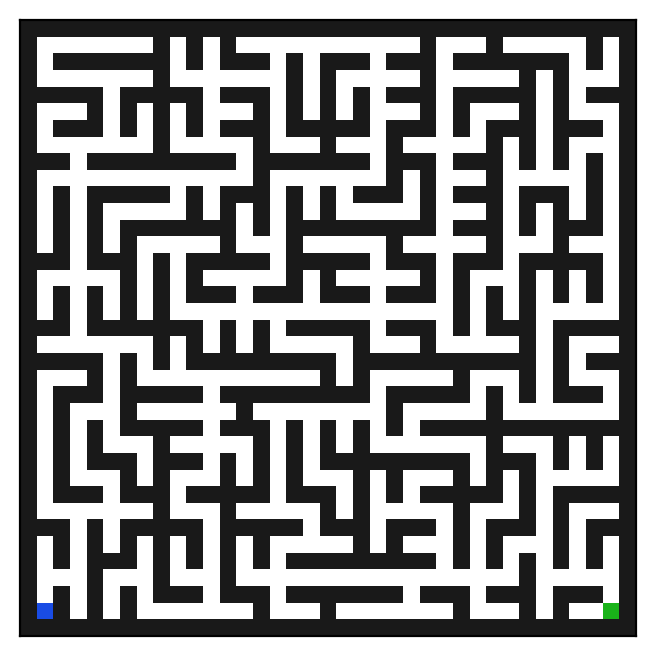

In [24]:
#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("L_maze.txt", "r")
#f = open("loops_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

ts.show_maze(maze)

ts.set_order(random=True)


In [25]:
import timeit
import math

reps = 10

times = {}

algorithms = ["BFS", "DFS", "GBFS", "A*"]

### FIXME: add IDS

for a in algorithms:
    times[a] = math.ceil(timeit.timeit(stmt = f'ts.best_first_search(maze, strategy = "{a}", debug = False, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)
    
times['DFS(no reached)'] = math.ceil(timeit.timeit(stmt = f'ts.DFS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

times['IDS'] = math.ceil(timeit.timeit(stmt = f'ts.IDS(maze, vis = False)', 
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

In [26]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,DFS(no reached),IDS
time in micro seconds,3791,3531,2878,3536,7246,725470


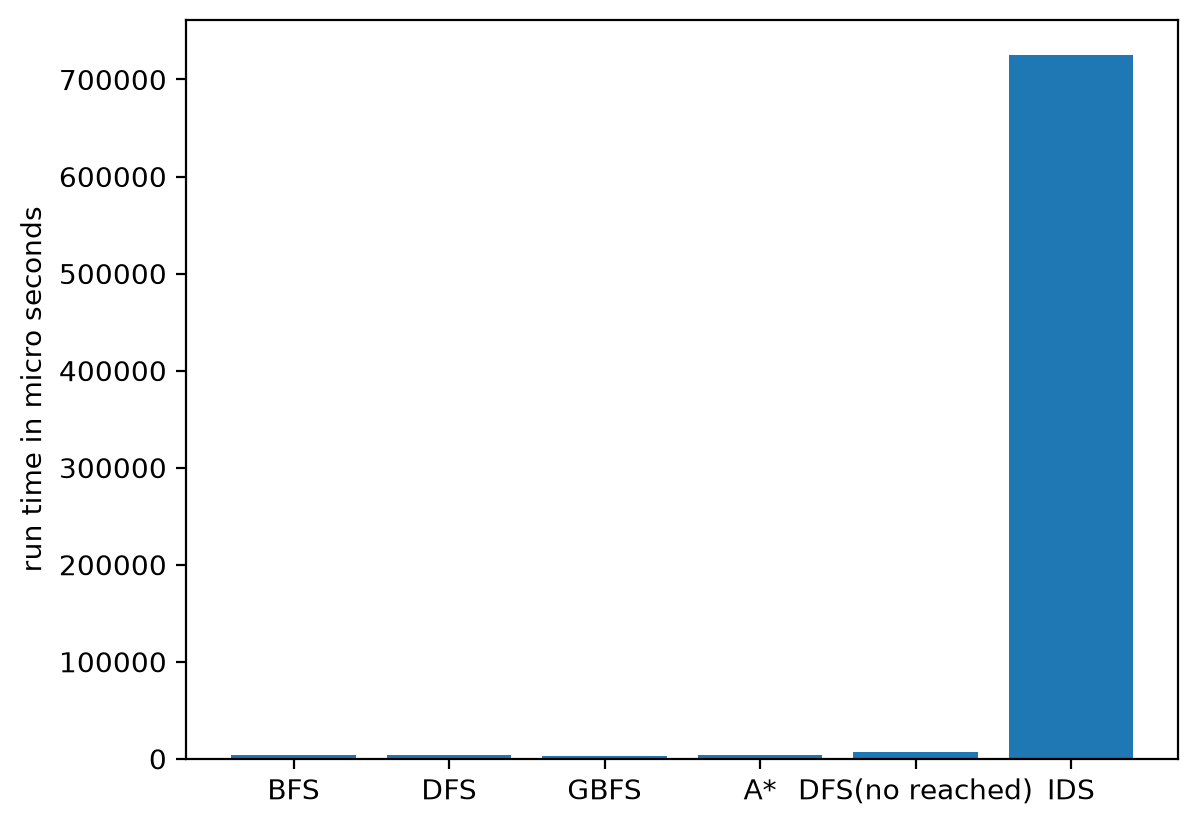

In [27]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()

#### Bảng kết quả

In [28]:
# ===== Bảng kết quả thí nghiệm (mục 4.2) =====
def best_of(fn, rep=5):
    return min((fn() for _ in range(rep)), key=lambda x: x["time"])

ALGOS = {
    "BFS":               lambda m: ts.best_first_search(m, strategy="BFS", debug=False, vis=False),
    "DFS + cycle check": lambda m: ts.DFS(m, max_tries=100000, vis=False),
    "GBFS (Manhattan)":  lambda m: ts.best_first_search(m, strategy="GBFS", debug=False, vis=False),
    "A* (Manhattan)":    lambda m: ts.best_first_search(m, strategy="A*", debug=False, vis=False),
    "A* (Euclidean)":    lambda m: ts.best_first_search(m, strategy="A*", debug=False, vis=False),
    "Weighted A* (w=5)": lambda m: ts.best_first_search(m, strategy="A*", W=5, debug=False, vis=False),
    "IDS":               lambda m: ts.IDS(m, frontier_option=2, max_tries=100000),
}
rows = []
for mname in ["small", "medium", "large", "open"]:
    mzz = load_maze(mname)
    for aname, fn in ALGOS.items():
        if aname == "IDS" and mname in ("large", "open"):
            continue                                  # IDS quá chậm trên mê cung lớn/nhiều ô trống (xem nhận xét)
        ts.heuristic = ts.euclidean if "Euclidean" in aname else ts.manhattan
        ts.set_order("NESW")
        r = best_of(lambda: fn(mzz), rep=3 if aname == "IDS" else 5)
        rows.append({"Maze": mname, "Thuật toán": aname, "Path cost": r["cost"], "Nút mở rộng": r["expanded"],
                     "Max depth": r["max_depth"], "Max frontier": r["max_frontier"],
                     "Thời gian (ms)": round(r["time"] * 1000, 2)})
ts.heuristic = ts.manhattan
results = pd.DataFrame(rows)
results.to_csv("ket_qua_thi_nghiem.csv", index=False)
display(results)

# Độ biến thiên của DFS khi thứ tự hướng đi ngẫu nhiên (liên quan câu thảo luận 7, 8)
mzz = load_maze("medium")
dfs_costs = []
for _ in range(20):
    ts.set_order(random=True); dfs_costs.append(ts.DFS(mzz, max_tries=100000, vis=False)["cost"])
ts.set_order("NESW")
print(f"DFS ngẫu nhiên (20 lần) trên medium: path cost nhỏ nhất {min(dfs_costs)}, lớn nhất {max(dfs_costs)}, "
      f"trung bình {sum(dfs_costs)/len(dfs_costs):.1f}; tối ưu (BFS) = {results[(results.Maze=='medium') & (results['Thuật toán']=='BFS')]['Path cost'].iloc[0]}")
orders = {}
for o in ["NESW", "SENW", "WSEN", "ENWS"]:
    ts.set_order(o); orders[o] = (ts.DFS(mzz, max_tries=100000, vis=False)["cost"], ts.best_first_search(mzz, strategy="BFS", debug=False, vis=False)["cost"])
ts.set_order("NESW")
print("Ảnh hưởng thứ tự sinh nút con (path cost DFS | BFS):", {k: f"{v[0]} | {v[1]}" for k, v in orders.items()})

,Maze,Thuật toán,Path cost,Nút mở rộng,Max depth,Max frontier,Thời gian (ms)
0,small,BFS,19.0,93,19,9,0.43
1,small,DFS + cycle check,37.0,94,44,5,0.58
2,small,GBFS (Manhattan),29.0,40,29,5,0.22
3,small,A* (Manhattan),19.0,52,19,7,0.31
4,small,A* (Euclidean),19.0,56,19,7,0.33
5,small,Weighted A* (w=5),29.0,42,29,5,0.26
6,small,IDS,19.0,1052,19,5,6.84
7,medium,BFS,68.0,270,68,9,1.14
8,medium,DFS + cycle check,244.0,268,244,14,3.06
9,medium,GBFS (Manhattan),152.0,156,152,8,0.74


DFS ngẫu nhiên (20 lần) trên medium: path cost nhỏ nhất 70, lớn nhất 238, trung bình 114.7; tối ưu (BFS) = 68.0
Ảnh hưởng thứ tự sinh nút con (path cost DFS | BFS): {'NESW': '244 | 68', 'SENW': '224 | 68', 'WSEN': '152 | 68', 'ENWS': '130 | 68'}
